#using library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,
                             confusion_matrix,
                             classification_report,
                             ConfusionMatrixDisplay)

In [ ]:
from google.colab import files
uploded=files.upload()

Saving german_credit_data.csv to german_credit_data.csv


In [ ]:
df=pd.read_csv('german_credit_data.csv')
df

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad
...,...,...,...,...,...,...,...,...,...,...,...
995,995,31,female,1,own,little,NaN,1736,12,furniture/equipment,good
996,996,40,male,3,own,little,little,3857,30,car,good
997,997,38,male,2,own,little,NaN,804,12,radio/TV,good
998,998,23,male,2,free,little,little,1845,45,radio/TV,bad


In [ ]:
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [ ]:
df.columns

Index(['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts',
       'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='object')

In [ ]:
df.shape

(1000, 11)

In [ ]:
df.nunique()

,0
Unnamed: 0,1000
Age,53
Sex,2
Job,4
Housing,3
Saving accounts,4
Checking account,3
Credit amount,921
Duration,33
Purpose,8


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,183
Checking account,394
Credit amount,0
Duration,0
Purpose,0


#remove unnacessary column

In [ ]:
df=df.drop('Unnamed: 0',axis=1)

In [ ]:
df["Risk"] = df["Risk"].map({"good": 0, "bad": 1})

In [ ]:
df['Risk'].value_counts()

,count
Risk,
0,700
1,300


#seperate features and target

In [ ]:
x=df.drop("Risk",axis=1)
y=df["Risk"]

In [ ]:
x

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,NaN,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,NaN,2096,12,education
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car
...,...,...,...,...,...,...,...,...,...
995,31,female,1,own,little,NaN,1736,12,furniture/equipment
996,40,male,3,own,little,little,3857,30,car
997,38,male,2,own,little,NaN,804,12,radio/TV
998,23,male,2,free,little,little,1845,45,radio/TV


In [ ]:
y

,Risk
0,0
1,1
2,0
3,0
4,1
...,...
995,0
996,0
997,0
998,1


#identify categorical and numerical column

In [ ]:
Categorical_column=x.select_dtypes(include=['object']).columns

In [ ]:
numerical_column=x.select_dtypes(exclude=["object"]).columns

In [ ]:
numerical_column

Index(['Age', 'Job', 'Credit amount', 'Duration'], dtype='object')

#preprocessing

In [ ]:
preprocessor=ColumnTransformer(transformers=[("num",StandardScaler(),numerical_column),("cat",OneHotEncoder(handle_unknown="ignore"),Categorical_column)])

#train_test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42,stratify=y)

#models

In [ ]:
models={
    "LogisticRegression":LogisticRegression(max_iter=1000),
    "Decision Tree":DecisionTreeClassifier(random_state=42),
    "Random Forest":RandomForestClassifier(n_estimators=200,random_state=42)
}

Training LogisticRegression...
Accuracy Score for LogisticRegression: 0.7350
Classification Report for LogisticRegression:
              precision    recall  f1-score   support

           0       0.77      0.89      0.83       140
           1       0.59      0.37      0.45        60

    accuracy                           0.73       200
   macro avg       0.68      0.63      0.64       200
weighted avg       0.72      0.73      0.71       200



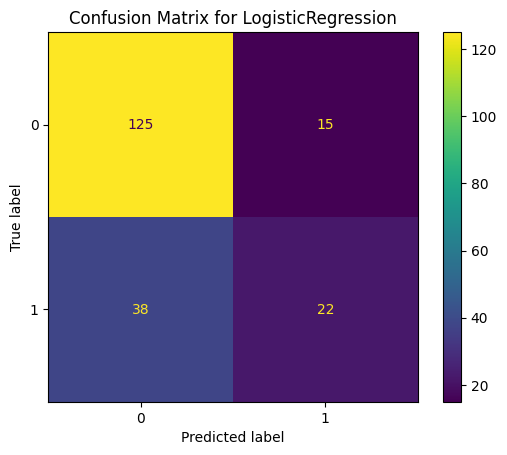

Training Decision Tree...
Accuracy Score for Decision Tree: 0.7100
Classification Report for Decision Tree:
              precision    recall  f1-score   support

           0       0.79      0.80      0.79       140
           1       0.52      0.50      0.51        60

    accuracy                           0.71       200
   macro avg       0.65      0.65      0.65       200
weighted avg       0.71      0.71      0.71       200



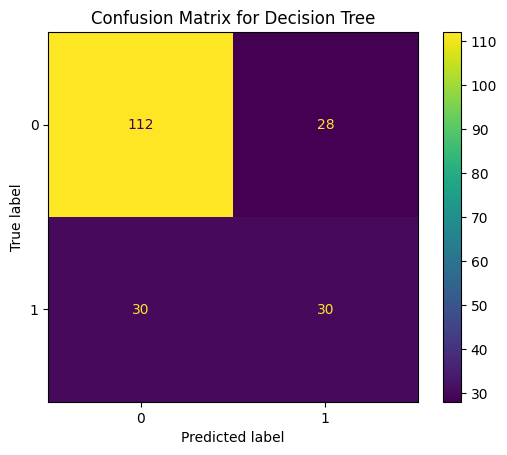

Training Random Forest...
Accuracy Score for Random Forest: 0.7600
Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.79      0.90      0.84       140
           1       0.65      0.43      0.52        60

    accuracy                           0.76       200
   macro avg       0.72      0.67      0.68       200
weighted avg       0.75      0.76      0.74       200



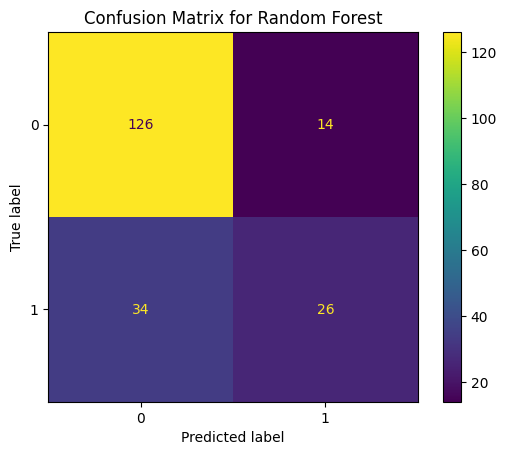


All model accuracies:
LogisticRegression: 0.7350
Decision Tree: 0.7100
Random Forest: 0.7600


In [ ]:
result = {}

for name, model in models.items():
    print(f'Training {name}...')
    # Create a pipeline for the current model, including the preprocessor
    current_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                       ('classifier', model)])

    current_pipeline.fit(X_train, y_train)
    y_pred = current_pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    result[name] = accuracy

    print(f'Accuracy Score for {name}: {accuracy:.4f}')
    print(f'Classification Report for {name}:\n{classification_report(y_test, y_pred)}')

    # Plot confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    try:
        display_labels = current_pipeline.named_steps['classifier'].classes_
    except AttributeError:
        display_labels = np.unique(y_test) # Fallback if model.classes_ not available

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
    disp.plot()
    plt.title(f'Confusion Matrix for {name}')
    plt.show()
    print('='*50)

print("\nAll model accuracies:")
for name, acc in result.items():
    print(f"{name}: {acc:.4f}")

#confusion matrix

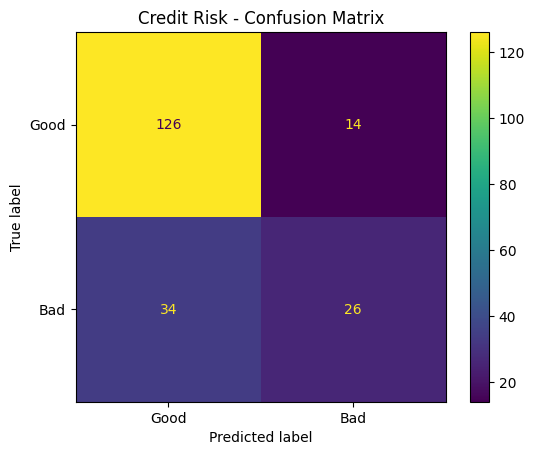

In [ ]:
best_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

best_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", best_model)
    ]
)

best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Good", "Bad"]
)

plt.title("Credit Risk - Confusion Matrix")
plt.show()

#predict a new customer

In [ ]:
new_customer = pd.DataFrame({
    "Age": [35],
    "Sex": ["male"],
    "Job": [2],
    "Housing": ["own"],
    "Saving accounts": ["moderate"],
    "Checking account": ["little"],
    "Credit amount": [5000],
    "Duration": [24],
    "Purpose": ["car"]
})

prediction = best_pipeline.predict(new_customer)

if prediction[0] == 0:
    print("Credit Risk: GOOD")
else:
    print("Credit Risk: BAD")














Credit Risk: GOOD
